In [1]:
# Install required dependencies if needed
%pip install torch torch-geometric rdkit pandas matplotlib scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 15.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 91.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torch-geometric]


## Overview


In [2]:
import random
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, GCNConv, global_mean_pool



## 1. Setup & Reproducibility


In [3]:
SEED = 7
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


## 2. Download and Load Dataset


In [4]:
url = 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv'
csv_path = 'bace.csv'

try:
    urllib.request.urlretrieve(url, csv_path)
except Exception as e:
    print(f"Using existing local file or failed download: {e}")

df = pd.read_csv(csv_path)
smiles_col = next(c for c in ['mol', 'smiles', 'SMILES'] if c in df.columns)
label_col = next(c for c in ['Class', 'label', 'Label', 'activity'] if c in df.columns)


## 3. Graph Construction


In [5]:
def smiles_to_graph(smiles, label=0):
    mol = Chem.MolFromSmiles(str(smiles))
    if not mol:
        return None, None

    # Atom features
    atom_features = [
        [
            atom.GetAtomicNum() / 100.0,
            atom.GetTotalDegree() / 6.0,
            atom.GetFormalCharge(),
            float(atom.GetIsAromatic()),
            float(atom.IsInRing()),
        ]
        for atom in mol.GetAtoms()
    ]

    # Bond edges (bidirectional)
    edges = []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        edges.extend([[i, j], [j, i]])

    edge_index = (
        torch.tensor(edges, dtype=torch.long).t().contiguous()
        if edges else torch.empty((2, 0), dtype=torch.long)
    )

    graph = Data(
        x=torch.tensor(atom_features, dtype=torch.float),
        edge_index=edge_index,
        y=torch.tensor([float(label)], dtype=torch.float),
        smiles=str(smiles)
    )
    return graph, mol

graphs, mols = [], []
for smi, lab in df[[smiles_col, label_col]].dropna().itertuples(index=False):
    g, m = smiles_to_graph(smi, lab)
    if g:
        graphs.append(g)
        mols.append(m)


## 4. BemisMurcko Scaffold Split


In [6]:
def get_scaffold(mol):
    return MurckoScaffold.MurckoScaffoldSmiles(mol=mol) or Chem.MolToSmiles(mol)

scaffold_groups = {}
for i, m in enumerate(mols):
    scaffold_groups.setdefault(get_scaffold(m), []).append(i)

grouped_indices = list(scaffold_groups.values())
random.shuffle(grouped_indices)

train_ids, val_ids, test_ids = [], [], []
n_total = len(graphs)

for group in grouped_indices:
    if len(train_ids) < 0.8 * n_total:
        train_ids.extend(group)
    elif len(val_ids) < 0.1 * n_total:
        val_ids.extend(group)
    else:
        test_ids.extend(group)

train_loader = DataLoader([graphs[i] for i in train_ids], batch_size=64, shuffle=True)
val_loader = DataLoader([graphs[i] for i in val_ids], batch_size=128)
test_loader = DataLoader([graphs[i] for i in test_ids], batch_size=128)


## 5. GNN Model Definition (GAT / GCN)


In [7]:
class MoleculeGNN(torch.nn.Module):
    def __init__(self, in_dim, model_type='GAT', hidden=32, heads=4, dropout=0.2):
        super().__init__()
        self.model_type = model_type
        self.dropout = dropout

        if model_type == 'GAT':
            self.conv1 = GATConv(in_dim, hidden, heads=heads, concat=True, dropout=dropout)
            self.conv2 = GATConv(hidden * heads, hidden, heads=1, concat=False, dropout=dropout)
        else:
            self.conv1 = GCNConv(in_dim, hidden)
            self.conv2 = GCNConv(hidden, hidden)

        self.out = torch.nn.Linear(hidden, 1)

    def forward(self, data):
        x = F.dropout(data.x, p=self.dropout, training=self.training)
        act = F.elu if self.model_type == 'GAT' else F.relu

        x = act(self.conv1(x, data.edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = act(self.conv2(x, data.edge_index))

        molecule = global_mean_pool(x, data.batch)
        return self.out(molecule).squeeze(-1)


## 6. Training Routine


In [8]:
def train(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-4)

    for epoch in range(1, 101):
        model.train()
        total_loss = 0.0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = F.binary_cross_entropy_with_logits(model(batch), batch.y.view(-1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        if epoch % 20 == 0:
            print(f"Epoch {epoch:03d} | Train Loss: {total_loss / len(train_loader):.4f}")

    return model

in_dim = graphs[0].x.size(1)

print("--- Training GAT Model ---")
gat_model = train(MoleculeGNN(in_dim, 'GAT').to(device))

print("\n--- Training GCN Model ---")
gcn_model = train(MoleculeGNN(in_dim, 'GCN').to(device))


--- Training GAT Model ---
Epoch 020 | Train Loss: 0.6768
Epoch 040 | Train Loss: 0.6717
Epoch 060 | Train Loss: 0.6680
Epoch 080 | Train Loss: 0.6682
Epoch 100 | Train Loss: 0.6707

--- Training GCN Model ---
Epoch 020 | Train Loss: 0.6742
Epoch 040 | Train Loss: 0.6774
Epoch 060 | Train Loss: 0.6692
Epoch 080 | Train Loss: 0.6676
Epoch 100 | Train Loss: 0.6734


## 7. Confusion Matrix Visualization


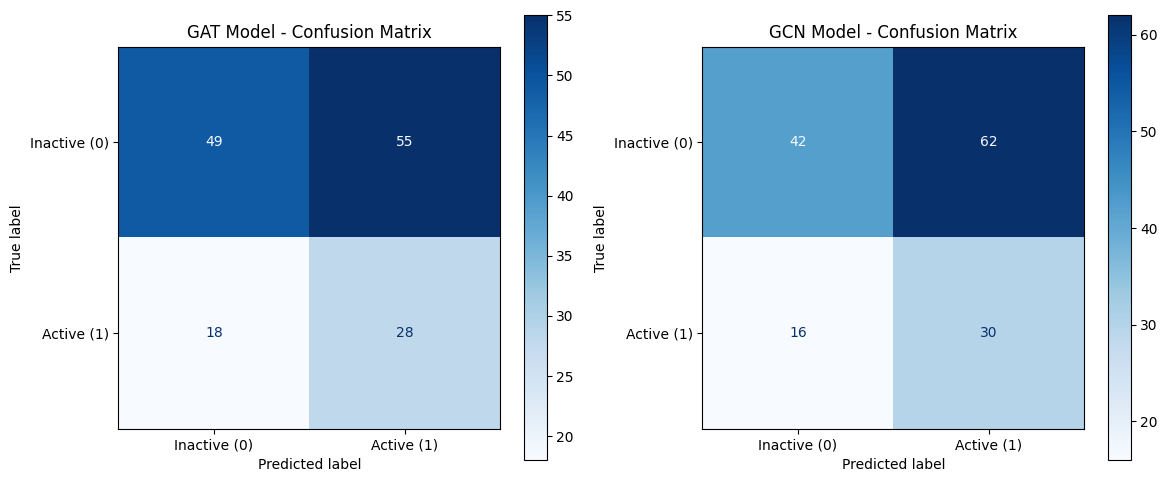

In [11]:
# -----------------------------------------------------------------------------
# 8. Confusion Matrix Visualization (GAT & GCN)
# -----------------------------------------------------------------------------
def evaluate_predictions(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs = torch.sigmoid(model(batch))
            preds = (probs >= 0.5).long()
            y_true.extend(batch.y.view(-1).cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    return np.array(y_true), np.array(y_pred)

# Get test predictions for GAT
y_true_gat, y_pred_gat = evaluate_predictions(gat_model, test_loader)
cm_gat = confusion_matrix(y_true_gat, y_pred_gat)

# Get test predictions for GCN
y_true_gcn, y_pred_gcn = evaluate_predictions(gcn_model, test_loader)
cm_gcn = confusion_matrix(y_true_gcn, y_pred_gcn)

# Plot both confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# GAT Matrix Plot
disp_gat = ConfusionMatrixDisplay(
    confusion_matrix=cm_gat,
    display_labels=['Inactive (0)', 'Active (1)']
)
disp_gat.plot(cmap=plt.cm.Blues, ax=axes[0], values_format='d')
axes[0].set_title('GAT Model - Confusion Matrix')

# GCN Matrix Plot
disp_gcn = ConfusionMatrixDisplay(
    confusion_matrix=cm_gcn,
    display_labels=['Inactive (0)', 'Active (1)']
)
disp_gcn.plot(cmap=plt.cm.Blues, ax=axes[1], values_format='d')
axes[1].set_title('GCN Model - Confusion Matrix')

plt.tight_layout()
plt.show()

## 8. External Inference on 10 DrugBank Compounds


In [12]:
# -----------------------------------------------------------------------------
# 8. External Inference on 10 DrugBank Compounds (GAT & GCN)
# -----------------------------------------------------------------------------
drugbank_samples = [
    {"id": "DB12285", "name": "Verubecestat", "smiles": "FC1=CC=C2N=C(N)NC(=O)[C@@]2(C)C1=CC=C(S(=O)(=O)C)C1=CC=NC=C1"},
    {"id": "DB11626", "name": "Atabecestat", "smiles": "FC1=CC=CC(=C1)C1(N=C(N)N(C)C1=O)C1=CC=CC(=C1)C#CC1=CN=CC=C1"},
    {"id": "DB06073", "name": "CTS-21166", "smiles": "CC(C)CC(C(C1=CC=CC=C1)NC(=O)C1=CC=CC=C1)O"},
    {"id": "DB19898", "name": "Umibecestat", "smiles": "CC1(C)CC(N=C(N)N1C)C1=C(F)C=CC(=C1)C1=CN=CC=C1"},
    {"id": "DB00316", "name": "Acetaminophen", "smiles": "CC(=O)NC1=CC=C(O)C=C1"},
    {"id": "DB01050", "name": "Ibuprofen", "smiles": "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O"},
    {"id": "DB00945", "name": "Aspirin", "smiles": "CC(=O)OC1=CC=CC=C1C(=O)O"},
    {"id": "DB00252", "name": "Phenytoin", "smiles": "O=C1NC(=O)C(N1)(C1=CC=CC=C1)C1=CC=CC=C1"},
    {"id": "DB00571", "name": "Propranolol", "smiles": "CC(C)NCC(O)COC1=CC=CC2=CC=CC=C12"},
    {"id": "DB00682", "name": "Warfarin", "smiles": "CC(=O)CC(C1=CC=CC=C1)C1=C(O)C2=CC=CC=C2OC1=O"}
]

external_graphs, valid_samples = [], []
for sample in drugbank_samples:
    graph, _ = smiles_to_graph(sample["smiles"], label=0)
    if graph:
        external_graphs.append(graph)
        valid_samples.append(sample)

external_loader = DataLoader(external_graphs, batch_size=len(external_graphs), shuffle=False)

def predict_external(model):
    model.eval()
    predictions = []
    with torch.no_grad():
        for batch in external_loader:
            batch = batch.to(device)
            probs = torch.sigmoid(model(batch)).cpu().numpy()
            predictions.extend(probs)
    return predictions

gat_preds = predict_external(gat_model)
gcn_preds = predict_external(gcn_model)

print("\n--- DrugBank External Predictions (BACE Activity Probability) ---")
print(f"{'ID':<10} | {'Name':<15} | {'GAT Prob':<10} | {'GCN Prob':<10}")
print("-" * 55)
for sample, gat_p, gcn_p in zip(valid_samples, gat_preds, gcn_preds):
    print(f"{sample['id']:<10} | {sample['name']:<15} | {gat_p:<10.4f} | {gcn_p:<10.4f}")


--- DrugBank External Predictions (BACE Activity Probability) ---
ID         | Name            | GAT Prob   | GCN Prob  
-------------------------------------------------------
DB12285    | Verubecestat    | 0.4777     | 0.4757    
DB11626    | Atabecestat     | 0.3429     | 0.4204    
DB06073    | CTS-21166       | 0.5642     | 0.6021    
DB19898    | Umibecestat     | 0.3236     | 0.3787    
DB00316    | Acetaminophen   | 0.5319     | 0.5877    
DB01050    | Ibuprofen       | 0.6625     | 0.6795    
DB00945    | Aspirin         | 0.6522     | 0.6703    
DB00252    | Phenytoin       | 0.3205     | 0.3886    
DB00571    | Propranolol     | 0.5567     | 0.5951    
DB00682    | Warfarin        | 0.4113     | 0.4950    
